In [3]:
# Manipulation des données
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Style général des graphiques
sns.set_theme(style="whitegrid")

In [4]:
# Création d'un jeu de données reproductible
df = pd.DataFrame({
    "ville": ["Dakar", "Dakar", "Thiès", "Thiès", "Saint-Louis",
              "Saint-Louis", "Dakar", "Thiès", "Dakar", "Saint-Louis"],
    "produit": ["Riz", "Huile", "Riz", "Savon", "Huile",
                "Riz", "Savon", "Riz", "Huile", "Savon"],
    "quantite": [20, 10, 15, 30, 12, 18, 25, 10, 8, 22],
    "prix_unitaire": [600, 1500, 600, 500, 1500, 600, 500, 600, 1500, 500]
})

# Calcul du chiffre d'affaires
df["chiffre_affaires"] = df["quantite"] * df["prix_unitaire"]

df.head()

,ville,produit,quantite,prix_unitaire,chiffre_affaires
0,Dakar,Riz,20,600,12000
1,Dakar,Huile,10,1500,15000
2,Thiès,Riz,15,600,9000
3,Thiès,Savon,30,500,15000
4,Saint-Louis,Huile,12,1500,18000


# A. Diagramme en barres — comparer des catégories

Quand l’utiliser ? Pour comparer le chiffre d’affaires entre les villes ou les produits.

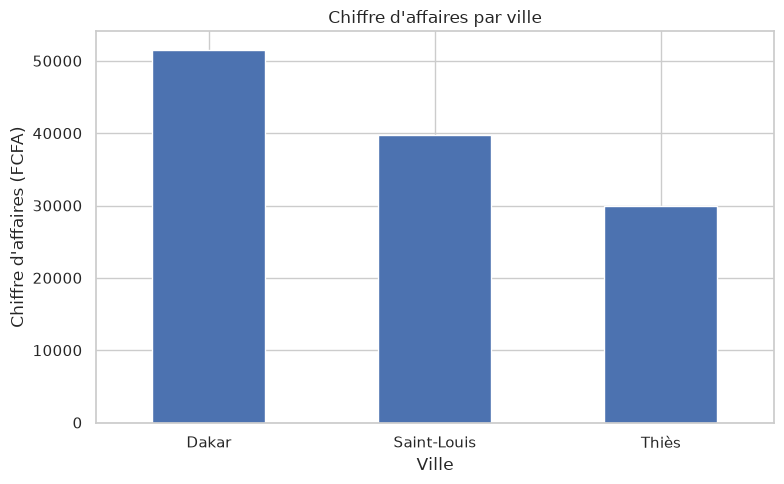

In [5]:
# Calculer le chiffre d'affaires par ville
ca_ville = df.groupby("ville")["chiffre_affaires"].sum()

# Créer le graphique
ca_ville.plot(kind="bar", figsize=(8, 5))

plt.title("Chiffre d'affaires par ville")
plt.xlabel("Ville")
plt.ylabel("Chiffre d'affaires (FCFA)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Interprétation : chaque barre représente le chiffre d’affaires total d’une ville. La hauteur permet de comparer les villes rapidement.

# B. Courbe — observer une évolution

Quand l’utiliser ? Pour suivre une variable dans le temps : ventes journalières, mensuelles ou annuelles.

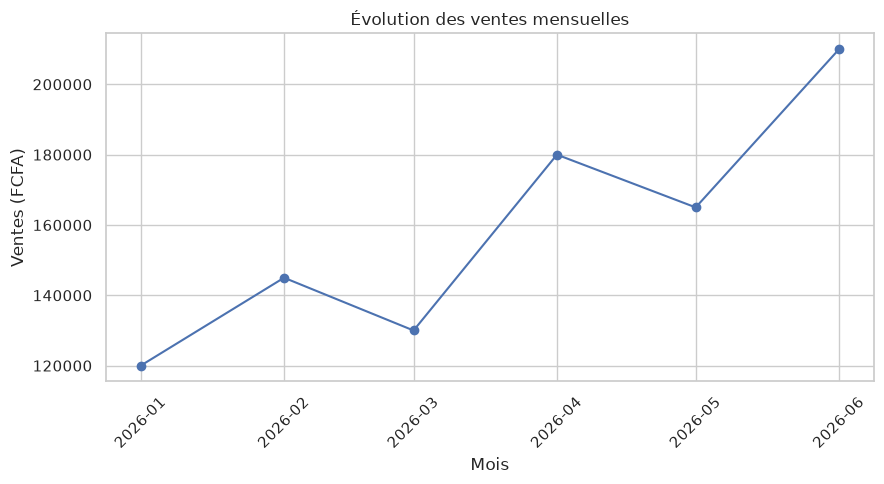

In [6]:
# Jeu de données mensuel fictif
ventes_mensuelles = pd.DataFrame({
    "mois": pd.date_range("2026-01-01", periods=6, freq="MS"),
    "ventes": [120000, 145000, 130000, 180000, 165000, 210000]
})

plt.figure(figsize=(9, 5))

plt.plot(
    ventes_mensuelles["mois"],
    ventes_mensuelles["ventes"],
    marker="o"
)

plt.title("Évolution des ventes mensuelles")
plt.xlabel("Mois")
plt.ylabel("Ventes (FCFA)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Interprétation : la courbe permet d’identifier les hausses, les baisses et les tendances. Ici, les ventes augmentent globalement, malgré quelques variations.

# C. Histogramme — comprendre une distribution

Quand l’utiliser ? Pour voir comment les valeurs d’une variable numérique sont réparties.

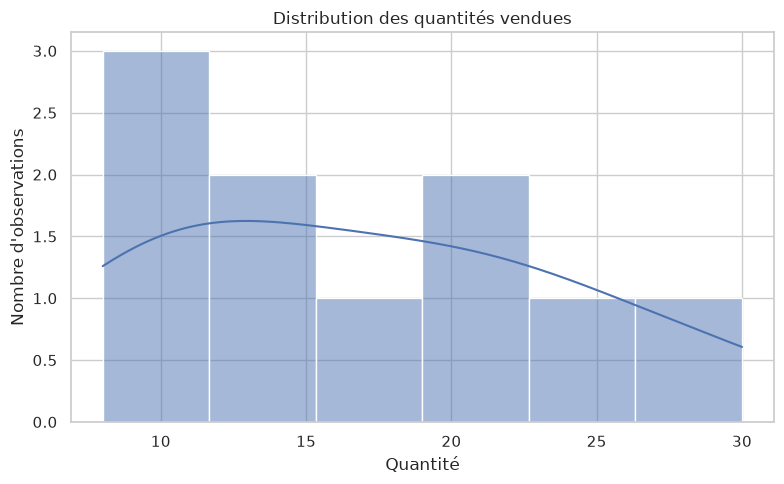

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="quantite", bins=6, kde=True)

plt.title("Distribution des quantités vendues")
plt.xlabel("Quantité")
plt.ylabel("Nombre d'observations")
plt.tight_layout()
plt.show()

# D. Nuage de points — étudier une relation
Quand l’utiliser ? Pour examiner la relation entre deux variables numériques.

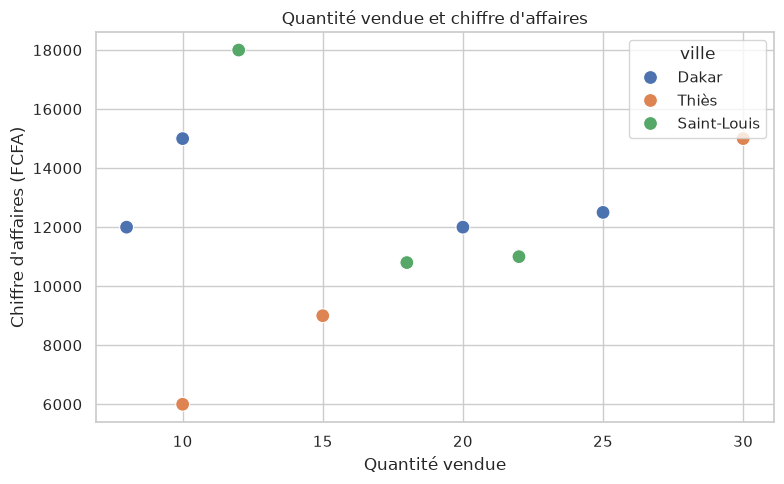

In [8]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="quantite",
    y="chiffre_affaires",
    hue="ville",
    s=100
)

plt.title("Quantité vendue et chiffre d'affaires")
plt.xlabel("Quantité vendue")
plt.ylabel("Chiffre d'affaires (FCFA)")
plt.tight_layout()
plt.show()

Interprétation : chaque point représente une vente. Les couleurs distinguent les villes. Le graphique permet de voir comment le chiffre d’affaires varie avec les quantités, mais aussi de repérer les ventes atypiques.

# E. Boîte à moustaches — détecter les valeurs atypiques
Quand l’utiliser ? Pour comparer la dispersion des valeurs et repérer d’éventuels points atypiques.

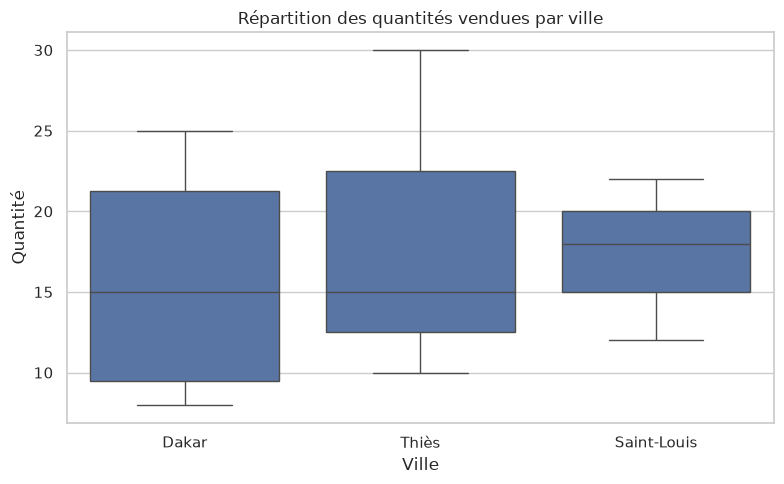

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="ville", y="quantite")

plt.title("Répartition des quantités vendues par ville")
plt.xlabel("Ville")
plt.ylabel("Quantité")
plt.tight_layout()
plt.show()

Interprétation : la boîte représente la partie centrale des données, la ligne centrale indique la médiane et les points situés au-delà des moustaches peuvent signaler des valeurs atypiques.

# Comparer plusieurs variables avec une agrégation
C’est une opération très courante en analyse de données : agréger avec Pandas, puis visualiser avec Seaborn.

In [10]:
# Calculer le chiffre d'affaires par ville et par produit
ca_par_ville_produit = (
    df.groupby(["ville", "produit"], as_index=False)
      ["chiffre_affaires"]
      .sum()
)

ca_par_ville_produit

,ville,produit,chiffre_affaires
0,Dakar,Huile,27000
1,Dakar,Riz,12000
2,Dakar,Savon,12500
3,Saint-Louis,Huile,18000
4,Saint-Louis,Riz,10800
5,Saint-Louis,Savon,11000
6,Thiès,Riz,15000
7,Thiès,Savon,15000


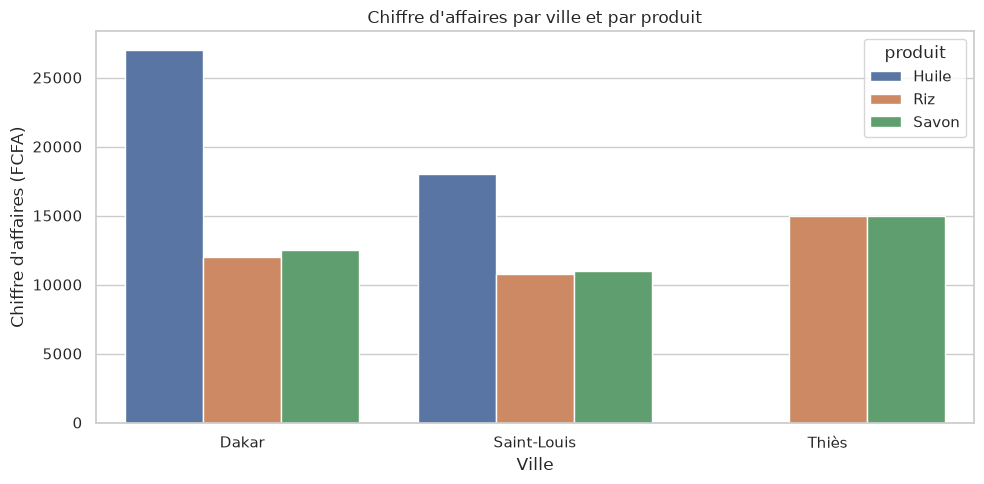

In [11]:
# Comparer les produits au sein de chaque ville
plt.figure(figsize=(10, 5))

sns.barplot(
    data=ca_par_ville_produit,
    x="ville",
    y="chiffre_affaires",
    hue="produit"
)

plt.title("Chiffre d'affaires par ville et par produit")
plt.xlabel("Ville")
plt.ylabel("Chiffre d'affaires (FCFA)")
plt.tight_layout()
plt.show()

# Personnaliser et enregistrer un graphique
Un graphique doit être compréhensible sans explication orale : titre précis, axes nommés, unités et légende si nécessaire.

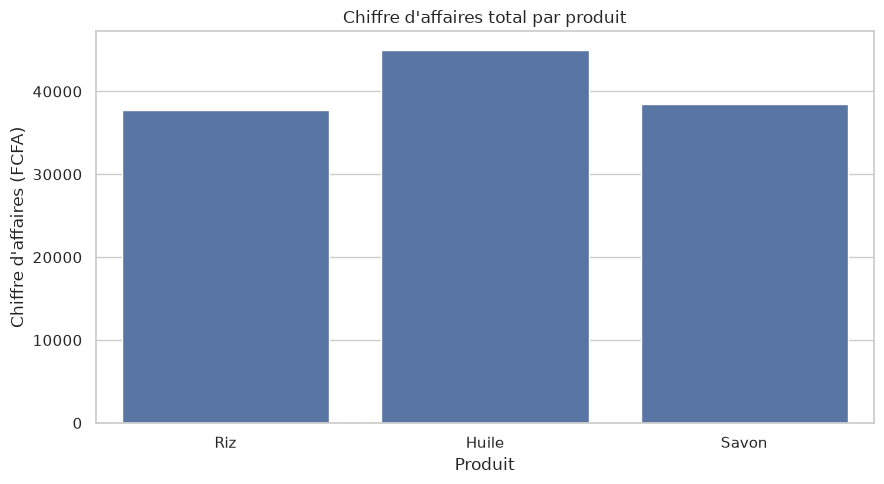

In [12]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="produit",
    y="chiffre_affaires",
    estimator="sum",
    errorbar=None
)

plt.title("Chiffre d'affaires total par produit")
plt.xlabel("Produit")
plt.ylabel("Chiffre d'affaires (FCFA)")
plt.tight_layout()

# Enregistrer le graphique avant de l'afficher
plt.savefig("chiffre_affaires_par_produit.png", dpi=150, bbox_inches="tight")

plt.show()

## Synthèse à retenir

| Besoin | Graphique conseillé |
|---|---|
| Comparer des catégories | Diagramme en barres |
| Suivre une évolution temporelle | Courbe |
| Comprendre la distribution d'une variable | Histogramme |
| Examiner une relation entre deux variables | Nuage de points |
| Comparer la dispersion et repérer des valeurs atypiques | Boîte à moustaches |

Le point essentiel n’est pas de connaître toutes les fonctions par cœur : c’est de choisir un graphique adapté à la question métier, de préparer les données correctement, puis d’interpréter le résultat.